# Задание 2.10* 
## Логарифмическая спираль на сфере Римана

### Условие:
Изобразите на сфере Римана логарифмическую спираль, заданную уравнением $r=ae^{b\varphi}$.

### Теория:
В плоскости $w=u+iv$ спираль задана параметрически: $w(\varphi)=ae^{b\varphi}e^{i\varphi}$, $\varphi\in\mathbb R$ (при $a,b>0$). При $\varphi\to-\infty$ имеем $w\to0$, при $\varphi\to+\infty$ имеем $w\to\infty$: спираль выходит из южного полюса $S=(0,0,-1)$ (образ $w=0$) и наматывается на северный полюс $N$ (образ $\infty$).

Стереографическая проекция: $(X,Y,Z)=\Bigl(\dfrac{2u}{|w|^2+1},\dfrac{2v}{|w|^2+1},\dfrac{|w|^2-1}{|w|^2+1}\Bigr)$. Если $\theta$ — угол от $N$ (т. е. $Z=\cos\theta$), то $|w|=\operatorname{ctg}\frac\theta2$, а долгота равна $\varphi$. Тогда из $r=ae^{b\varphi}$ получаем
$$
\varphi=\frac1b\Bigl(\ln\operatorname{ctg}\frac\theta2-\ln a\Bigr)\ \Rightarrow\ \sin\theta\,\frac{d\varphi}{d\theta}=-\frac1b,
$$
то есть кривая пересекает все меридианы под одним и тем же углом $\alpha$, $\operatorname{tg}\alpha=1/b$. Значит, образ логарифмической спирали — **локсодромия** (румб). Это согласуется с конформностью проекции: спираль под постоянным углом пересекает лучи из начала координат, а их образы — меридианы.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

a, b = 1.0, 0.15
phi = np.linspace(-45, 45, 40001)                 # около 14 оборотов
w = a*np.exp(b*phi)*np.exp(1j*phi)

def to_sphere(w):
    s = abs(w)**2 + 1
    return 2*w.real/s, 2*w.imag/s, (abs(w)**2 - 1)/s

X, Y, Z = to_sphere(w)
print('точка на сфере:', np.allclose(X**2 + Y**2 + Z**2, 1))
print(f'начало (φ=−45): ({X[0]:.4f}, {Y[0]:.4f}, {Z[0]:.4f})  — вблизи южного полюса S')
print(f'конец  (φ=+45): ({X[-1]:.4f}, {Y[-1]:.4f}, {Z[-1]:.4f})  — вблизи северного полюса N')

точка на сфере: True
начало (φ=−45): (0.0012, -0.0020, -1.0000)  — вблизи южного полюса S
конец  (φ=+45): (0.0012, 0.0020, 1.0000)  — вблизи северного полюса N


### Проверка: угол с меридианами постоянен ($\operatorname{tg}\alpha=1/b$)

In [2]:
theta = np.arccos(Z)                              # угол от N
lam = np.unwrap(np.arctan2(Y, X))                 # долгота
dth, dlam = np.gradient(theta, phi), np.gradient(lam, phi)
tan_alpha = np.abs(np.sin(theta)*dlam/dth)        # tg угла между кривой и меридианом
mid = slice(2000, -2000)                          # без краёв, где численная производная неточна
print(f'1/b = {1/b:.6f};  tg α: среднее = {tan_alpha[mid].mean():.6f},  разброс = {tan_alpha[mid].std():.2e}')
print(f'угол с меридианами α = {np.degrees(np.arctan(1/b)):.3f}°')

1/b = 6.666667;  tg α: среднее = 6.666667,  разброс = 7.31e-08
угол с меридианами α = 81.469°


### Изображение: спираль на плоскости и на сфере Римана

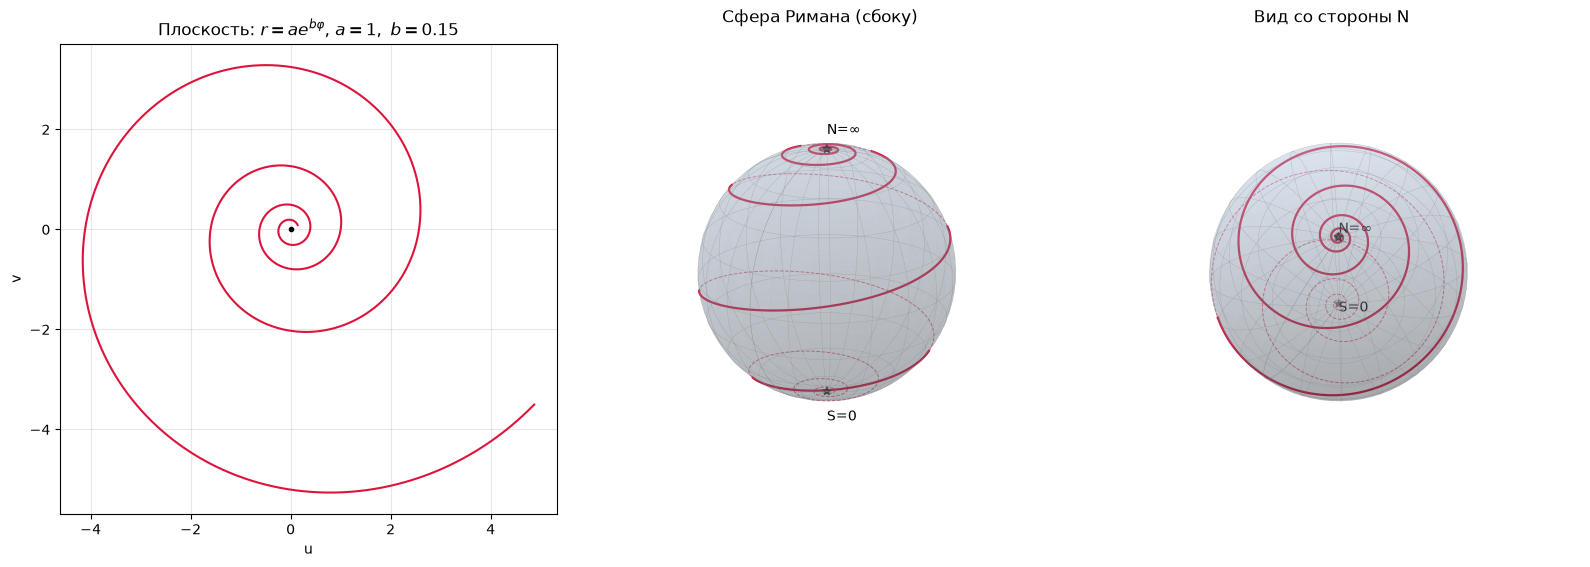

In [3]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

def draw_sphere(ax):
    u = np.linspace(0, 2*np.pi, 80); v = np.linspace(0, np.pi, 40)
    xs, ys, zs = np.outer(np.cos(u), np.sin(v)), np.outer(np.sin(u), np.sin(v)), np.outer(np.ones_like(u), np.cos(v))
    ax.plot_surface(xs, ys, zs, color='lightsteelblue', alpha=0.25, linewidth=0, shade=True)
    ax.plot_wireframe(xs, ys, zs, color='gray', lw=0.25, alpha=0.5, rstride=4, cstride=4)

def draw_curve(ax, elev, azim):
    d = np.array([np.cos(np.radians(elev))*np.cos(np.radians(azim)),
                  np.cos(np.radians(elev))*np.sin(np.radians(azim)), np.sin(np.radians(elev))])
    front = X*d[0] + Y*d[1] + Z*d[2] >= 0
    ax.plot(np.where(front, X, np.nan), np.where(front, Y, np.nan), np.where(front, Z, np.nan), color='crimson', lw=1.6)
    ax.plot(np.where(~front, X, np.nan), np.where(~front, Y, np.nan), np.where(~front, Z, np.nan),
            color='crimson', lw=0.7, ls='--', alpha=0.6)

fig = plt.figure(figsize=(16, 5.5))

ax = fig.add_subplot(1, 3, 1)
sel = (phi > -12) & (abs(w) < 6)
ax.plot(w.real[sel], w.imag[sel], color='crimson')
ax.plot(0, 0, 'k.')
ax.set_aspect('equal'); ax.grid(alpha=0.3)
ax.set_title(r'Плоскость: $r=ae^{b\varphi}$, $a=1,\ b=0.15$'); ax.set_xlabel('u'); ax.set_ylabel('v')

for i, (elev, azim, title) in enumerate([(20, 35, 'Сфера Римана (сбоку)'), (75, 35, 'Вид со стороны N')], 2):
    ax = fig.add_subplot(1, 3, i, projection='3d')
    draw_sphere(ax); draw_curve(ax, elev, azim)
    ax.scatter([0, 0], [0, 0], [1, -1], color='k', s=35, marker='*')
    ax.text(0, 0, 1.12, 'N=∞'); ax.text(0, 0, -1.25, 'S=0')
    ax.view_init(elev=elev, azim=azim); ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
    ax.set_title(title)
plt.tight_layout()
plt.show()

### Ответ:

Образ логарифмической спирали $r=ae^{b\varphi}$ на сфере Римана — локсодромия: кривая, выходящая из южного полюса $S$ ($\varphi\to-\infty$) и бесконечно наматывающаяся на северный полюс $N$ ($\varphi\to+\infty$) и пересекающая все меридианы под постоянным углом $\alpha=\operatorname{arctg}\frac1b$ (для $b=0{,}15$ угол $\approx81{,}5^\circ$).